<a href="https://colab.research.google.com/github/eduardozurek/ia/blob/main/_009_SVM_maquinas_de_soporte_vectorial/02_SVM_Kernel_Lineal_con_Outliers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## MÁQUINAS DE SOPORTE VECTORIAL - SVM - SUPPORT-VECTOR MACHINES
### Las SVM son separadores no lineales que se construyen a partir de separadores lineales y se generalizan con la aplicación de kernels. Las SVM permiten encontrar límites entre conjuntos que se sobrelapan.

### Las implementaciones presentadas aquí se basan en el capítulo 12 de:

[1]	H. Trevor, T. Robert, y F. JH, The elements of statistical learning: data mining, inference, and prediction. New York, NY: Springer, 2009.

### También es muy buena la descripción presentada en:
https://towardsdatascience.com/understanding-support-vector-machine-part-1-lagrange-multipliers-5c24a52ffc5e
### Y
https://towardsdatascience.com/understanding-support-vector-machine-part-2-kernel-trick-mercers-theorem-e1e6848c6c4d

### Y la clase de MIT-OCW del Dr. Patrick Winston:
https://www.youtube.com/watch?v=_PwhiWxHK8o


     pcost       dcost       gap    pres   dres
 0: -1.7188e+01 -1.9458e+01  6e+02  2e+01  3e-15
 1: -3.0348e+00 -1.8137e+01  3e+01  8e-01  3e-15
 2: -2.0950e+00 -6.6819e+00  5e+00  3e-16  1e-15
 3: -2.6787e+00 -3.4082e+00  7e-01  2e-16  1e-15
 4: -2.9164e+00 -3.1232e+00  2e-01  2e-16  9e-16
 5: -2.9825e+00 -3.0460e+00  6e-02  4e-16  8e-16
 6: -3.0054e+00 -3.0181e+00  1e-02  6e-16  1e-15
 7: -3.0110e+00 -3.0115e+00  4e-04  2e-16  9e-16
 8: -3.0112e+00 -3.0112e+00  4e-06  5e-16  1e-15
 9: -3.0112e+00 -3.0112e+00  4e-08  3e-16  1e-15
Optimal solution found.


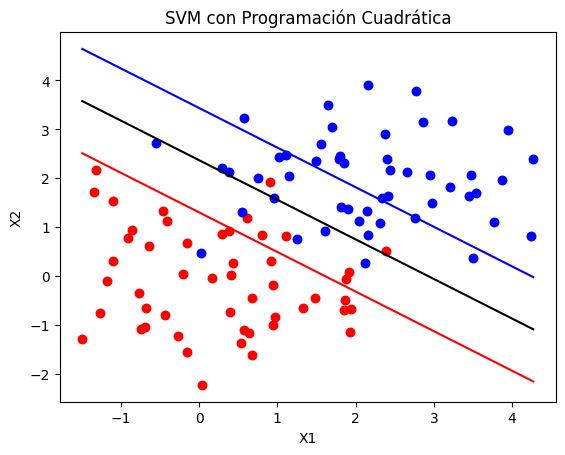

In [ ]:
import numpy as np
from cvxopt import matrix, solvers
import matplotlib.pyplot as plt

# Generación de datos aleatorios
n = 50
np.random.seed(0)  # Semilla para reproducibilidad
x11 = np.random.randn(n, 1) + 2
x12 = np.random.randn(n, 1) + 2
x21 = np.random.randn(n, 1)
x22 = np.random.randn(n, 1)
y1 = np.ones((n, 1))
y2 = -np.ones((n, 1))
x = np.vstack((np.hstack((x11, x12)), np.hstack((x21, x22))))
y = np.vstack((y1, y2)).reshape(-1)

# Preparación de las matrices para la programación cuadrática
H = np.zeros((n * 2, n * 2))
for k in range(n * 2):
    for l in range(n * 2):
        H[k, l] = y[k] * y[l] * np.dot(x[k], x[l])
H = 0.5 * H
q = -np.ones(n * 2)
A = y.reshape(1, -1).astype(float)
b = np.zeros(1)
G = np.vstack((-np.eye(n * 2), np.eye(n * 2)))
h = np.hstack((np.zeros(n * 2), np.ones(n * 2) * 0.1))

# Convertir a matrices cvxopt
H = matrix(H)
q = matrix(q)
A = matrix(A)
b = matrix(b)
G = matrix(G)
h = matrix(h)

# Resolver el problema de programación cuadrática
sol = solvers.qp(H, q, G, h, A, b)
alphas = np.array(sol['x'])

# Calcular w
w = np.sum(alphas * y.reshape(-1, 1) * x, axis=0) / 2

# Calcular el ancho
ancho = 2 / np.linalg.norm(w)

# Identificar vectores de soporte
umbral = 1e-5
mask=alphas>umbral
mask=mask.T
mask=mask[0]
xt = x[mask]
yt = y[mask]

# Calcular b
t = np.dot(xt, w) - yt
b = np.mean(t)

# Crear líneas para graficar
x_range = np.linspace(min(x[:, 0]), max(x[:, 0]), num=100)
y1 = -x_range * w[0] / w[1] + b + 1
y2 = y1 - ancho / 2
y3 = y1 + ancho / 2

# Graficar
plt.scatter(x[y < 0, 0], x[y < 0, 1], color='r', marker='.', s=150)
plt.scatter(x[y >= 0, 0], x[y >= 0, 1], color='b', marker='.', s=150)
plt.plot(x_range, y1, 'k')
plt.plot(x_range, y2, 'r')
plt.plot(x_range, y3, 'b')
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('SVM con Programación Cuadrática')
plt.show()
